# 06 · Revisión: inferencia agrupada por centro

**Objetivo.** Reestimar la incertidumbre de los efectos de 04 agrupando los errores por centro. Es una revisión posterior a la exposición del análisis.

**Justificación: cómo surgió esta revisión.** En los notebooks 04 y 05, el equipo estimó el ITT y el LATE con errores robustos a nivel de cada madre (HC3), sin agrupar por centro. El razonamiento fue que las madres se sortearon *dentro* de cada centro, y no se sortearon centros. En la exposición, el instructor preguntó por qué no se había estimado por conglomerados. La respuesta dada, "solo fueron 5 centros", fue insuficiente. Que haya pocos centros es una dificultad *técnica* para agrupar, no un motivo para no hacerlo.

La pregunta de fondo era **a qué población se quieren aplicar las conclusiones**. El caso describe que la municipalidad amplió el horario en cinco de sus centros. Si esos cinco centros se entienden como una muestra de la red municipal, la pregunta de política es qué pasaría al ampliar el horario en *otros* centros, y esa incertidumbre debe entrar en la inferencia.

> **En sencillo — qué cambia y qué no:** los **efectos estimados** (cuánto sube el empleo) no cambian, porque se calculan con la misma regresión. Lo que cambia es **cuánta confianza** tenemos en ellos, es decir, el margen de error y los valores $p$.

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

In [2]:
# Base analítica generada en 01_datos_auditoria_construccion.ipynb
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe la base analítica. Ejecute primero 01_datos_auditoria_construccion.ipynb"
    )
df = pd.read_csv(PROCESSED)
print(f"Base analítica: {df.shape[0]} filas x {df.shape[1]} columnas")

Base analítica: 1500 filas x 28 columnas


In [3]:
from itertools import product
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from linearmodels.iv import IV2SLS

NOMBRES = {"empleo_post": "Empleo (pp)", "horas_post": "Horas semanales",
           "ingreso_post_c": "Ingreso mensual (u.m.)", "bienestar_post": "Bienestar (0-100)"}
ESCALA = {"empleo_post": 100}
CONTROLES = f"C({CENTER}) + " + " + ".join(BASELINE)
G = df[CENTER].nunique()
T_CRIT = stats.t.ppf(0.975, G - 1)      # valor crítico t con G-1 = 4 grados de libertad
print(f"Centros (conglomerados): {G}; valor crítico t(4) al 95 % = {T_CRIT:.2f} (frente a 1.96 de la normal)")

Centros (conglomerados): 5; valor crítico t(4) al 95 % = 2.78 (frente a 1.96 de la normal)


## 6.1 ¿Cuándo hay que agrupar los errores?

**Fundamento metodológico.** Abadie, Athey, Imbens y Wooldridge [1] identifican **dos** motivos para agrupar los errores por conglomerado, y basta con uno:

| Motivo | ¿Aplica en este caso? |
|---|---|
| **El tratamiento se asignó por grupos** (por ejemplo, sortear centros enteros) | **No:** el sorteo fue madre por madre, dentro de cada centro (02.2) |
| **Los grupos son una muestra de una población más amplia de grupos**, a la que se quiere generalizar | **Sí:** los 5 centros son una muestra de la red municipal, y la política se aplicaría en otros centros |

El equipo solo consideró el primer motivo; el relevante era el segundo.

> **En sencillo — por qué importa de dónde vienen los centros:** imagina que la municipalidad hubiera elegido otros cinco centros. El sorteo de madres habría sido igual de limpio, pero el efecto promedio sería distinto, porque los centros difieren en calidad, en barrio y en oportunidades laborales cercanas. Los errores HC3 solo miden la incertidumbre de *qué madres* se sortearon. Los errores agrupados miden además la de *qué centros* se eligieron.

## 6.2 El efecto varía entre centros

**Objetivo.** Mostrar con los datos que el efecto no es el mismo en todos los centros: esa es la fuente de incertidumbre que el agrupamiento captura.

,n,itt_pp,ee_pp
centro,,,
1,301,5.460,5.722
2,303,7.788,5.794
3,292,11.655,5.630
4,314,8.204,5.529
5,290,18.193,5.667


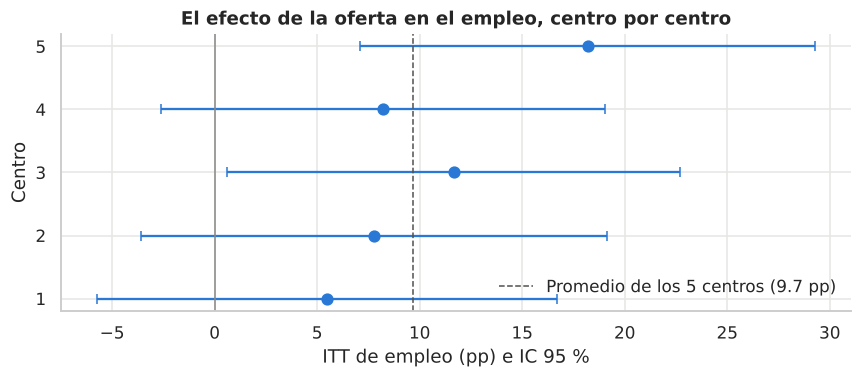

Empleo (pp)              H0 efecto igual en los 5 centros: chi2(4) = 3.30, p = 0.51
Horas semanales          H0 efecto igual en los 5 centros: chi2(4) = 3.78, p = 0.44
Ingreso mensual (u.m.)   H0 efecto igual en los 5 centros: chi2(4) = 5.00, p = 0.29
Bienestar (0-100)        H0 efecto igual en los 5 centros: chi2(4) = 2.14, p = 0.71


In [4]:
# ITT de empleo estimado por separado en cada centro (covariables previas, errores HC3)
por_centro = []
for c, g in df.groupby(CENTER):
    m = smf.ols(f"empleo_post ~ {Z} + " + " + ".join(BASELINE), data=g).fit(cov_type="HC3")
    por_centro.append({"centro": c, "n": len(g), "itt_pp": 100 * m.params[Z], "ee_pp": 100 * m.bse[Z]})
por_centro = pd.DataFrame(por_centro).set_index("centro")
display(por_centro)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(por_centro["itt_pp"], por_centro.index.astype(str), xerr=1.96 * por_centro["ee_pp"],
            fmt="o", color=COLORS[1], capsize=3, ms=7)
ax.axvline(9.66, color="#52514e", ls="--", lw=1, label="Promedio de los 5 centros (9.7 pp)")
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_xlabel("ITT de empleo (pp) e IC 95 %"); ax.set_ylabel("Centro")
ax.set_title("El efecto de la oferta en el empleo, centro por centro")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

# Prueba formal: ¿el efecto es igual en los 5 centros? (interacciones Z x centro, Wald HC3)
for y in OUTCOMES:
    m = smf.ols(f"{y} ~ {Z} * C({CENTER}) + " + " + ".join(BASELINE), data=df.dropna(subset=[y])).fit(cov_type="HC3")
    inter = [n for n in m.params.index if n.startswith(f"{Z}:")]
    w = m.wald_test(", ".join(f"{n} = 0" for n in inter), scalar=True)
    print(f"{NOMBRES[y]:<24} H0 efecto igual en los 5 centros: chi2(4) = {w.statistic:.2f}, p = {w.pvalue:.2f}")

**Interpretación**

- El efecto en el empleo, estimado centro por centro, va de **5.5 pp (centro 1) a 18.2 pp (centro 5)**. A simple vista, la política parece rendir el triple en un centro que en otro.
- **Pero cada estimación es muy imprecisa:** con unas 300 madres por centro, su error estándar es de unos 5.6 pp y los intervalos se superponen ampliamente. La prueba formal **no rechaza que el efecto sea igual en los cinco centros** (p = 0.51 en empleo y entre 0.29 y 0.71 en los demás resultados).
- **Esto no debilita el argumento para agrupar, lo refuerza.** No sabemos si los centros difieren poco o mucho: con cinco centros, los datos no alcanzan para medirlo. Si la municipalidad quiere saber qué pasaría en *otros* centros, esa ignorancia sobre la variación entre centros es parte de la incertidumbre, y los errores agrupados son los que la incorporan.

## 6.3 Por qué no basta el error agrupado estándar

**Fundamento metodológico.** El error estándar agrupado habitual (CR1) supone que hay *muchos* conglomerados. Con pocos, es inestable: puede subestimar o sobrestimar la incertidumbre [2, 3]. Se compara con HC3 para ver ese comportamiento.

In [5]:
comp = []
for y in OUTCOMES:
    d = df.dropna(subset=[y])
    f = f"{y} ~ {Z} + {CONTROLES}"
    e = ESCALA.get(y, 1)
    hc3 = smf.ols(f, data=d).fit(cov_type="HC3")
    cr1 = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d[CENTER]})
    comp.append({"resultado": NOMBRES[y], "itt": e * hc3.params[Z], "ee_HC3": e * hc3.bse[Z],
                 "ee_agrupado_CR1": e * cr1.bse[Z], "cambio_%": 100 * (cr1.bse[Z] / hc3.bse[Z] - 1)})
display(pd.DataFrame(comp).set_index("resultado"))

,itt,ee_HC3,ee_agrupado_CR1,cambio_%
resultado,,,,
Empleo (pp),9.661,2.481,2.266,-8.662
Horas semanales,5.486,0.936,0.913,-2.385
Ingreso mensual (u.m.),188.807,37.249,41.182,10.560
Bienestar (0-100),3.421,0.528,0.371,-29.712


**Interpretación**

- Con 5 conglomerados, el error agrupado estándar se comporta de forma **errática**. En el ingreso sube 11 % respecto de HC3, como se esperaría, pero en el bienestar **cae 30 %** y en el empleo 9 %. Eso sugeriría *más* precisión al agrupar, lo cual no tiene sentido sustantivo.
- La razón es estadística: con solo cinco "observaciones" a nivel de centro, la estimación de la varianza entre centros es muy ruidosa. Por eso no basta reportar el error agrupado estándar, y se recurre a procedimientos diseñados para pocos conglomerados.

## 6.4 Inferencia para pocos conglomerados: wild cluster bootstrap

**Fundamento metodológico.** Se usan dos procedimientos adecuados para 5 conglomerados:

1. **Errores agrupados con valores críticos de $t$ con $G-1 = 4$ grados de libertad**, en lugar de la normal (1.96). El valor crítico es 2.78, así que exige más evidencia [2].
2. **Wild cluster bootstrap restringido con pesos de Webb** [3, 4]. Se impone la hipótesis nula (sin efecto), se multiplican los residuos de cada centro por un mismo peso aleatorio y se recalcula el estadístico. El valor $p$ es la proporción de réplicas con un estadístico al menos tan extremo como el observado. Con 5 centros y los 6 pesos de Webb hay $6^5 = 7\,776$ combinaciones, y se recorren todas, sin simulación aleatoria.

> **En sencillo — wild cluster bootstrap:** es como "volver a barajar" los datos, pero respetando que las madres de un mismo centro se mueven juntas: a todo un centro le toca el mismo "golpe de suerte". Así la incertidumbre se mide al nivel de los centros, que es donde está el problema. Los pesos de Webb son una forma de repartir esos golpes que funciona bien con muy pocos grupos. Con solo dos valores posibles por centro habría apenas 32 combinaciones, demasiado pocas.

In [6]:
WEBB = np.array([-np.sqrt(1.5), -1, -np.sqrt(0.5), np.sqrt(0.5), 1, np.sqrt(1.5)])

def wild_cluster_bootstrap(data, formula, termino, grupos=CENTER):
    # Valor p del wild cluster bootstrap restringido (H0: coef. de `termino` = 0), pesos de Webb, enumeración completa
    completo = smf.ols(formula, data=data).fit()
    X, y = completo.model.exog, completo.model.endog
    nombres = completo.model.exog_names
    j = nombres.index(termino)
    g = data[grupos].to_numpy(); centros = np.unique(g)
    n_g, (n, k) = len(centros), X.shape
    Xr = X[:, [i for i in range(k) if i != j]]                 # modelo restringido (impone H0)
    br = np.linalg.lstsq(Xr, y, rcond=None)[0]
    ajuste0, resid0 = Xr @ br, y - Xr @ br
    A = np.linalg.inv(X.T @ X) @ X.T
    corr = n_g / (n_g - 1) * (n - 1) / (n - k)                   # corrección CR1
    def t_agrupado(Y):
        B = A @ Y; E = Y - X @ B
        var = sum((A[j, g == c] @ E[g == c]) ** 2 for c in centros) * corr
        return B[j] / np.sqrt(var)
    t_obs = t_agrupado(y[:, None])[0]
    pesos = np.array(list(product(WEBB, repeat=n_g)))           # 7 776 combinaciones
    idx = np.searchsorted(centros, g)
    t_boot = t_agrupado(ajuste0[:, None] + resid0[:, None] * pesos[:, idx].T)
    # Las 6 combinaciones con el mismo peso en todos los centros reproducen exactamente t_obs.
    # Se cuentan como "al menos tan extremas" (convención); la tolerancia evita que el redondeo decida.
    return float(np.mean(np.abs(t_boot) >= abs(t_obs) - 1e-10))

filas = []
for y in OUTCOMES:
    d = df.dropna(subset=[y]).reset_index(drop=True)
    f = f"{y} ~ {Z} + {CONTROLES}"
    e = ESCALA.get(y, 1)
    hc3 = smf.ols(f, data=d).fit(cov_type="HC3")
    cr1 = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d[CENTER]})
    b, ee = cr1.params[Z], cr1.bse[Z]
    filas.append({"resultado": y, "itt": e * b, "p_HC3": hc3.pvalues[Z],
                  "p_agrupado_t4": 2 * stats.t.sf(abs(b / ee), G - 1),
                  "p_wild_bootstrap": wild_cluster_bootstrap(d, f, Z),
                  "ic_inf_t4": e * (b - T_CRIT * ee), "ic_sup_t4": e * (b + T_CRIT * ee)})
agr = pd.DataFrame(filas).set_index("resultado")
sec = ["horas_post", "ingreso_post_c", "bienestar_post"]
agr.loc[sec, "p_wild_holm"] = multipletests(agr.loc[sec, "p_wild_bootstrap"], method="holm")[1]
display(agr.rename(index=NOMBRES).style.format({"itt": "{:.2f}", "p_HC3": "{:.1e}", "p_agrupado_t4": "{:.3f}",
    "p_wild_bootstrap": "{:.3f}", "ic_inf_t4": "{:.1f}", "ic_sup_t4": "{:.1f}", "p_wild_holm": "{:.3f}"}, na_rep="primario"))

,itt,p_HC3,p_agrupado_t4,p_wild_bootstrap,ic_inf_t4,ic_sup_t4,p_wild_holm
resultado,,,,,,,
Empleo (pp),9.66,9.9e-05,0.013,0.026,3.4,16.0,primario
Horas semanales,5.49,4.5e-09,0.004,0.020,3.0,8.0,0.039
Ingreso mensual (u.m.),188.81,4.0e-07,0.010,0.019,74.5,303.1,0.039
Bienestar (0-100),3.42,9.3e-11,0.001,0.013,2.4,4.5,0.039


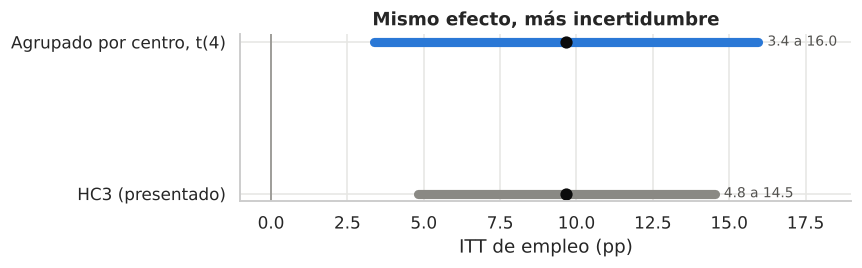

In [7]:
# Comparación visual del IC 95 % del empleo: HC3 (presentado) frente a agrupado t(4)
d = df
f = f"empleo_post ~ {Z} + {CONTROLES}"
hc3 = smf.ols(f, data=d).fit(cov_type="HC3")
ic = {"HC3 (presentado)": (100 * hc3.conf_int().loc[Z, 0], 100 * hc3.conf_int().loc[Z, 1]),
      "Agrupado por centro, t(4)": (agr.loc["empleo_post", "ic_inf_t4"], agr.loc["empleo_post", "ic_sup_t4"])}
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (k, (lo, hi)) in enumerate(ic.items()):
    ax.plot([lo, hi], [i, i], color=[NEUTRAL, COLORS[1]][i], lw=6, solid_capstyle="round")
    ax.text(hi + 0.3, i, f"{lo:.1f} a {hi:.1f}", va="center", fontsize=9, color="#52514e")
ax.plot([agr.loc["empleo_post", "itt"]] * 2, [0, 1], "o", color="#0b0b0b", ms=7)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_yticks([0, 1], list(ic.keys())); ax.set_xlabel("ITT de empleo (pp)"); ax.set_xlim(-1, 19)
ax.set_title("Mismo efecto, más incertidumbre")
plt.tight_layout(); plt.show()

**Interpretación**

| Resultado | Efecto | $p$ HC3 (presentado) | $p$ wild cluster bootstrap | IC 95 % agrupado, $t(4)$ |
|---|---|---|---|---|
| Empleo | +9.7 pp | < 0.001 | **0.026** | 3.4 a 16.0 |
| Horas semanales | +5.5 | < 0.001 | **0.020** | 3.0 a 8.0 |
| Ingreso mensual | +189 u.m. | < 0.001 | **0.019** | 74 a 303 |
| Bienestar | +3.4 | < 0.001 | **0.013** | 2.4 a 4.5 |

- **Los cuatro efectos siguen siendo significativos al 5 %**, también después de corregir con Holm los tres resultados secundarios ($p$ = 0.039). Pero están **bastante más cerca del umbral** que con HC3.
- **El intervalo del empleo se amplía de [4.8, 14.5] a [3.4, 16.0].** En términos de política: de cada 100 madres a las que se ofrece la vacante, se esperarían entre 3 y 16 madres adicionales trabajando. El efecto es positivo con bastante seguridad, pero su magnitud en otros centros es incierta.
- El intervalo del bienestar casi no cambia porque el error agrupado de ese resultado es inestable (6.3). Para bienestar conviene guiarse por el valor $p$ del wild cluster bootstrap (0.013) más que por el intervalo.

## 6.5 El efecto de usar el servicio (LATE) con errores agrupados

**Fundamento metodológico.** Se reestima el 2SLS de 04.6 con errores agrupados por centro, con la misma corrección para pocos conglomerados que en el ITT (CR1), y valores críticos $t(4)$. Con un único instrumento, la prueba de que el LATE es cero equivale a la prueba de la forma reducida, es decir, del ITT. Por eso comparte el valor $p$ del wild cluster bootstrap de 6.4.

In [8]:
fs = smf.ols(f"{D} ~ {Z} + {CONTROLES}", data=df).fit(cov_type="cluster", cov_kwds={"groups": df[CENTER]})
print(f"Primera etapa π = {fs.params[Z]:.3f} (EE agrupado {fs.bse[Z]:.3f}); F efectivo agrupado = {(fs.params[Z] / fs.bse[Z]) ** 2:,.0f}")

def ic(lo, hi, dec):
    return f"{lo:,.{dec}f} a {hi:,.{dec}f}"

filas = []
for y in OUTCOMES:
    d = df.dropna(subset=[y]).reset_index(drop=True)
    e, dec = ESCALA.get(y, 1), (0 if y == "ingreso_post_c" else 1)
    modelo = IV2SLS.from_formula(f"{y} ~ 1 + {CONTROLES} + [{D} ~ {Z}]", data=d)
    rob = modelo.fit(cov_type="robust")                                               # HC0, como en 04.6
    # debiased=True aplica la corrección CR1 (G/(G-1) y (n-1)/(n-k)), igual que en el ITT
    agr_iv = modelo.fit(cov_type="clustered", clusters=d[CENTER], debiased=True)
    b, ee_r, ee_c = agr_iv.params[D], rob.std_errors[D], agr_iv.std_errors[D]
    filas.append({
        "Resultado": NOMBRES[y],
        "LATE": f"{e * b:,.{dec}f}",
        "IC 95 % robusto (04.6)": ic(e * (b - 1.96 * ee_r), e * (b + 1.96 * ee_r), dec),
        "IC 95 % agrupado, t(4)": ic(e * (b - T_CRIT * ee_c), e * (b + T_CRIT * ee_c), dec),
        "p (wild cluster bootstrap)": f"{agr.loc[y, 'p_wild_bootstrap']:.3f}",
    })
tabla_late = pd.DataFrame(filas).set_index("Resultado")
display(tabla_late.style.set_caption("Efecto de usar el servicio (LATE) entre las cumplidoras: inferencia robusta (04.6) frente a agrupada por centro"))

Primera etapa π = 0.624 (EE agrupado 0.032); F efectivo agrupado = 379


,LATE,IC 95 % robusto (04.6),"IC 95 % agrupado, t(4)",p (wild cluster bootstrap)
Resultado,,,,
Empleo (pp),15.5,7.9 a 23.1,6.1 a 24.9,0.026
Horas semanales,8.8,6.0 a 11.6,5.3 a 12.3,0.020
Ingreso mensual (u.m.),302,189 a 415,151 a 454,0.019
Bienestar (0-100),5.5,3.9 a 7.1,4.4 a 6.6,0.013


**Interpretación**

| Resultado | LATE | IC 95 % robusto (04.6) | IC 95 % agrupado, $t(4)$ | $p$ wild cluster bootstrap |
|---|---|---|---|---|
| Empleo | +15.5 pp | 7.9 a 23.1 | **6.1 a 24.9** | 0.026 |
| Horas semanales | +8.8 | 6.0 a 11.6 | **5.3 a 12.3** | 0.020 |
| Ingreso mensual | +302 u.m. | 189 a 415 | **151 a 454** | 0.019 |
| Bienestar | +5.5 | 3.9 a 7.1 | **4.4 a 6.6** | 0.013 |

- **El sorteo sigue siendo un instrumento fuerte** con errores agrupados: F ≈ 379, muy por encima del umbral de 104.7.
- **El efecto de usar el servicio** entre las cumplidoras se mantiene en +15.5 pp de empleo. Su intervalo agrupado, de **6.1 a 24.9 pp**, es más amplio que el de 04.6 (7.9 a 23.1). Para el ingreso va de 151 a 454 u.m.
- **En bienestar, el intervalo agrupado es más angosto que el robusto.** Es la misma inestabilidad del error agrupado con cinco centros que se vio en 6.3, no una ganancia real de precisión. Para ese resultado conviene guiarse por el valor $p$ del wild cluster bootstrap.
- Las conclusiones de 04 sobre el LATE no cambian en dirección ni en significancia.

## 6.6 Diferencias por subgrupos con errores agrupados

**Fundamento metodológico.** Se repiten las interacciones de 04.8 (subgrupos definidos en 00) con inferencia agrupada: valor $p$ del wild cluster bootstrap para la interacción $Z \times M$ y corrección de Holm por resultado.

In [9]:
MODERADORES = {"madre_sola": "Madre sola", "sin_red": "Sin red de cuidado",
               "restriccion_alta": "Sola y sin red", "empleo_pre": "Trabajaba antes"}
EXCLUIR = {"sin_red": {"red_cuidado"}, "restriccion_alta": {"madre_sola", "red_cuidado"}}
filas = []
for y in OUTCOMES:
    d = df.dropna(subset=[y]).reset_index(drop=True)
    e = ESCALA.get(y, 1)
    for m_, nombre in MODERADORES.items():
        covs = [v for v in BASELINE if v != m_ and v not in EXCLUIR.get(m_, set())]
        f = f"{y} ~ {Z} * {m_} + C({CENTER}) + " + " + ".join(covs)
        r = smf.ols(f, data=d).fit()
        filas.append({"resultado": NOMBRES[y], "moderador": nombre,
                      "itt_subgrupo": e * (r.params[Z] + r.params[f"{Z}:{m_}"]), "itt_resto": e * r.params[Z],
                      "diferencia": e * r.params[f"{Z}:{m_}"], "p_wild_bootstrap": wild_cluster_bootstrap(d, f, f"{Z}:{m_}")})
het = pd.DataFrame(filas)
het["p_holm"] = het.groupby("resultado")["p_wild_bootstrap"].transform(lambda p: multipletests(p, method="holm")[1])
display(het.set_index(["resultado", "moderador"]))

itt_subgrupo  itt_resto  diferencia  p_wild_bootstrap  p_holm
resultado              moderador                                                                        
Empleo (pp)            Madre sola                 6.469     11.052      -4.583             0.696   1.000
                       Sin red de cuidado        11.889      6.792       5.097             0.414   1.000
                       Sola y sin red            11.423      9.292       2.130             0.833   1.000
                       Trabajaba antes           12.073      7.530       4.543             0.461   1.000
Horas semanales        Madre sola                 2.922      6.604      -3.683             0.377   1.000
                       Sin red de cuidado         5.614      5.322       0.292             0.890   1.000
                       Sola y sin red             3.593      5.854      -2.261             0.784   1.000
                       Trabajaba antes            7.219      3.956       3.264             0.248   0.994
Ingreso mensual (u.m.) Madre sola               108.728    223.808    -115.080             0.522   1.000
                       Sin red de cuidado       213.470    157.340      56.131             0.582   1.000
                       Sola y sin red           179.633    190.648     -11.014             0.953   1.000
                       Trabajaba antes          232.916    149.979      82.937             0.408   1.000
Bienestar (0-100)      Madre sola                 2.997      3.606      -0.608             0.664   1.000
                       Sin red de cuidado         3.734      3.018       0.716             0.590   1.000
                       Sola y sin red             4.074      3.302       0.772             0.583   1.000
                       Trabajaba antes            3.268      3.556      -0.287             0.671   1.000

**Interpretación**

- **Con errores agrupados, ninguna diferencia entre subgrupos se acerca a la significancia.** En empleo, los valores $p$ van de 0.41 a 0.83. En todos los resultados, el menor es 0.25 (horas, "trabajaba antes"). Con Holm, prácticamente todos son 1.
- La conclusión de 04.8 se refuerza: **no hay evidencia para focalizar el programa en algún subgrupo.** Esto no significa que el efecto sea igual para todas: el estudio no tiene poder para distinguir diferencias moderadas, y menos aún con inferencia agrupada.

## 6.7 Síntesis: qué cambia, qué no y qué aprendimos

| | Análisis presentado (04-05) | Revisión (06) |
|---|---|---|
| Efectos estimados (ITT, LATE) | Empleo +9.7 pp; LATE +15.5 pp | **Iguales** |
| Inferencia | HC3, a nivel de madre | **Agrupada por centro:** wild cluster bootstrap (pesos de Webb) y $t(4)$ |
| Significancia del ITT | $p$ < 0.001 en los 4 resultados | $p$ entre 0.013 y 0.026: **sigue siendo significativo** |
| IC 95 % del empleo | 4.8 a 14.5 pp | **3.4 a 16.0 pp** |
| Subgrupos | Sin diferencias significativas | **Sin diferencias**, con evidencia aún más débil |
| A qué se generaliza | A las postulantes de estos 5 centros | **A otros centros de la red municipal**, con la incertidumbre correspondiente |

**Qué significa para la política.** La conclusión de fondo se mantiene: ofrecer horario ampliado aumenta el empleo de las madres. Lo que la revisión agrega es prudencia sobre la **magnitud** esperada si la municipalidad amplía el horario en otros centros: podría ir de 3 a 16 madres adicionales empleadas por cada 100. Antes de escalar, conviene medir los resultados centro por centro.

**Lección metodológica.** La decisión de agrupar no depende solo de **cómo se asignó el tratamiento**, sino también de **cómo se eligieron las unidades y a qué población se quiere generalizar** [1]. Que haya pocos conglomerados no es un motivo para no agrupar: es un motivo para usar métodos diseñados para pocos conglomerados [3].

**Decisión.** Para conclusiones sobre la red municipal, la inferencia de referencia es la de este notebook. La de 04 vale para las postulantes de los cinco centros evaluados.

## Referencias

1. Abadie, A., Athey, S., Imbens, G. W. y Wooldridge, J. M. (2023). When should you adjust standard errors for clustering? *Quarterly Journal of Economics*, 138(1), 1-35. https://doi.org/10.1093/qje/qjac038
2. Cameron, A. C. y Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources*, 50(2), 317-372. https://doi.org/10.3368/jhr.50.2.317
3. MacKinnon, J. G. y Webb, M. D. (2018). The wild bootstrap for few (treated) clusters. *The Econometrics Journal*, 21(2), 114-135.
4. Webb, M. D. (2023). Reworking wild bootstrap-based inference for clustered errors. *Canadian Journal of Economics*, 56(3), 839-858. https://doi.org/10.1111/caje.12661